In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy import stats

# Configuración visual de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Carga del archivo oficial de matrículas con el motor de Python robusto
df_raw = pd.read_csv('MEN_MATRICULA_ESTADISTICA_ES_20261023.csv', engine='python', on_bad_lines='skip')

print("¡Archivo cargado exitosamente!")
print("Dimensiones iniciales del dataset:", df_raw.shape)
print("\nEstadísticas descriptivas de la matrícula:")
print(df_raw['Total Matriculados'].describe())

¡Archivo cargado exitosamente!
Dimensiones iniciales del dataset: (390903, 26)

Estadísticas descriptivas de la matrícula:
count    390903.000000
mean         63.734567
std         118.231419
min           1.000000
25%           5.000000
50%          17.000000
75%          63.000000
max         999.000000
Name: Total Matriculados, dtype: float64


In [ ]:
# ==========================================
# SECCIÓN 3: LIMPIEZA Y TRANSFORMACIÓN
# ==========================================

# 1. Copia de trabajo para proteger el DataFrame original
df = df_raw.copy()

# 2. Estandarización de nombres de columnas (minúsculas, sin espacios ni caracteres especiales)
df.columns = df.columns.str.lower().str.strip().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

# 3. Eliminación de registros duplicados
total_duplicados = df.duplicated().sum()
df = df.drop_duplicates()
print(f"Registros duplicados eliminados: {total_duplicados}")

# 4. Tratamiento de valores faltantes en la variable principal de estudio
# Justificación: Se imputan los valores nulos con la mediana para evitar el sesgo de valores atípicos
nulos_antes = df['total_matriculados'].isnull().sum()
df['total_matriculados'] = df['total_matriculados'].fillna(df['total_matriculados'].median())
print(f"Valores faltantes imputados en 'total_matriculados': {nulos_antes}")

# 5. Filtrado del año más reciente disponible para un análisis focalizado y consistente
anio_reciente = df['año'].max()
df_reciente = df[df['año'] == anio_reciente].copy()

print(f"\n¡Limpieza completada exitosamente!")
print(f"Año analizado: {anio_reciente}")
print(f"Dimensiones finales del dataset limpio: {df_reciente.shape}")

Registros duplicados eliminados: 106599
Valores faltantes imputados en 'total_matriculados': 0

¡Limpieza completada exitosamente!
Año analizado: 2021
Dimensiones finales del dataset limpio: (34562, 26)


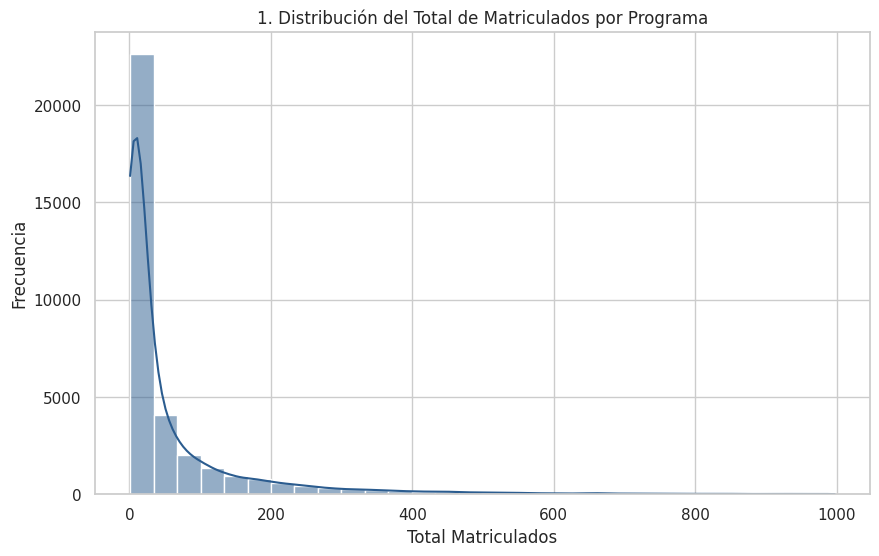

/tmp/ipykernel_8069/42279484.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_reciente, x='id_sector', y='total_matriculados', palette='Set2')


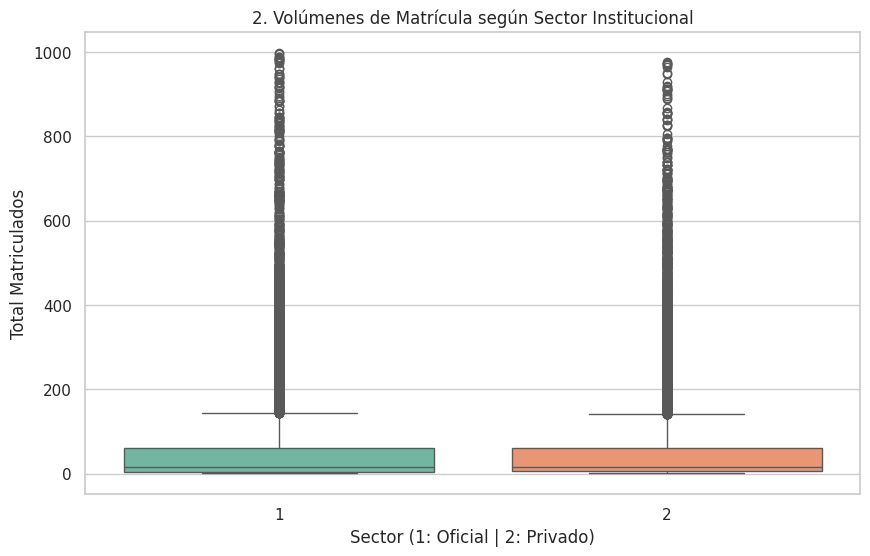

/tmp/ipykernel_8069/42279484.py:24: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(
/tmp/ipykernel_8069/42279484.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


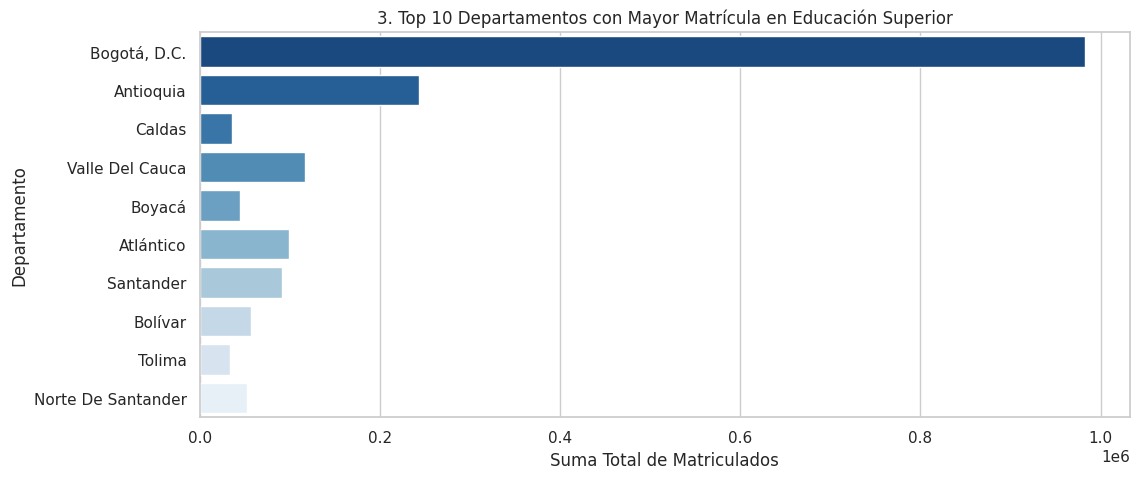

In [ ]:
# ==========================================
# SECCIÓN 4: ANÁLISIS EXPLORATORIO (EDA)
# ==========================================

# Gráfico 1: Histograma de la distribución del total de matriculados
plt.figure()
sns.histplot(df_reciente['total_matriculados'], bins=30, kde=True, color='#2b5c8f')
plt.title("1. Distribución del Total de Matriculados por Programa")
plt.xlabel("Total Matriculados")
plt.ylabel("Frecuencia")
plt.show()

# Gráfico 2: Diagrama de caja (Boxplot) por Sector (1: Oficial, 2: Privado)
plt.figure()
sns.boxplot(data=df_reciente, x='id_sector', y='total_matriculados', palette='Set2')
plt.title("2. Volúmenes de Matrícula según Sector Institucional")
plt.xlabel("Sector (1: Oficial | 2: Privado)")
plt.ylabel("Total Matriculados")
plt.show()

# Gráfico 3: Top 10 Departamentos con mayor volumen de matrícula
plt.figure(figsize=(12, 5))
top_depts = df_reciente.groupby('departamento_de_domicilio_de_la_ies')['total_matriculados'].sum().nlargest(10).index
sns.barplot(
    data=df_reciente[df_reciente['departamento_de_domicilio_de_la_ies'].isin(top_depts)],
    y='departamento_de_domicilio_de_la_ies',
    x='total_matriculados',
    estimator=sum,
    ci=None,
    palette='Blues_r'
)
plt.title("3. Top 10 Departamentos con Mayor Matrícula en Educación Superior")
plt.xlabel("Suma Total de Matriculados")
plt.ylabel("Departamento")
plt.show()

# Gráfico 5: Gráfico interactivo con Plotly (Sector y Metodología)
fig_plotly = px.box(
    df_reciente,
    x="id_sector",
    y="total_matriculados",
    color="id_metodologia",
    title="4. Análisis Interactivo: Matrícula por Sector y Metodología",
    labels={"id_sector": "Sector IES", "total_matriculados": "Total Matriculados"}
)
fig_plotly.show()

In [ ]:
# ==========================================
# SECCIÓN 5: PRUEBA DE HIPÓTESIS / ESTADÍSTICA
# ==========================================

# 1. Separación de los grupos de estudio según el sector institucional
oficial = df_reciente[df_reciente['id_sector'] == 1]['total_matriculados']
privado = df_reciente[df_reciente['id_sector'] == 2]['total_matriculados']

# 2. Aplicación de la prueba t de Student para muestras independientes (Welch's t-test)
# Justificación: No asumimos varianzas iguales entre las universidades públicas y privadas
t_stat, p_val = stats.ttest_ind(oficial, privado, equal_var=False)

# 3. Impresión de resultados detallados
print("--- RESULTADOS DE LA PRUEBA T DE STUDENT ---")
print(f"Estadístico t: {t_stat:.4f}")
print(f"Valor p (p-value): {p_val:.4e}")

# 4. Evaluación de la hipótesis
alpha = 0.05
if p_val < alpha:
    print("\nConclusión estadística: Se rechaza la hipótesis nula (H0).")
    print("Existen diferencias estadísticamente significativas en los volúmenes de matrícula entre el sector oficial y el privado.")
else:
    print("\nConclusión estadística: No se rechaza la hipótesis nula (H0).")
    print("No se aprecian diferencias significativas entre ambos sectores.")

--- RESULTADOS DE LA PRUEBA T DE STUDENT ---
Estadístico t: -0.7982
Valor p (p-value): 4.2475e-01

Conclusión estadística: No se rechaza la hipótesis nula (H0).
No se aprecian diferencias significativas entre ambos sectores.
